# 03 Modelling and evaluation
Out-of-time split: train on 2015-16..2022-23 (2014-15 is only Elo warm-up), test on 2023-24 and 2024-25, 2025-26 is an incomplete partial check. Hyper-parameters chosen by expanding-window CV on train only.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, json, matplotlib.pyplot as plt, config
from src import evaluation as ev
figs = config.FIGURES_DIR
mt = pd.read_csv(config.METRICS_FILE)
mt[mt['set']=='test'][['model','accuracy','log_loss','RPS','Brier','cv_log_loss','selected_by_cv']].round(4)

,model,accuracy,log_loss,RPS,Brier,cv_log_loss,selected_by_cv
0,Baseline: always home win,0.4337,1.0678,0.2345,0.6466,NaN,False
2,Baseline: Elo only (logistic),0.5570,0.9618,0.1976,0.5715,0.9906,False
4,Logistic Regression,0.5584,0.9631,0.1973,0.5725,0.9916,True
6,Random Forest,0.5544,0.9773,0.2015,0.5803,0.9953,False
8,Gradient Boosting,0.5557,0.9784,0.1988,0.5789,1.0035,False


In [2]:
print(json.dumps(json.load(open(config.REPORTS_DIR/'bootstrap_best_vs_baselines.json')), indent=1))

{
 "best_model": "Logistic Regression",
 "vs_always_home": {
  "accuracy": {
   "diff": 0.12466843501326252,
   "lo": 0.08753315649867377,
   "hi": 0.16047745358090187
  },
  "log_loss": {
   "diff": -0.1046570940438657,
   "lo": -0.13088000229982236,
   "hi": -0.07828745500620313
  }
 },
 "vs_elo_only": {
  "accuracy": {
   "diff": 0.0013262599469495706,
   "lo": -0.01061007957559679,
   "hi": 0.01326259946949604
  },
  "log_loss": {
   "diff": 0.0013540918546202096,
   "lo": -0.004902689008738112,
   "hi": 0.007233693663169596
  }
 }
}


Reading: the selected model beats always-home clearly (interval excludes 0) but is indistinguishable from the Elo-only baseline.

In [3]:
pd.read_csv(config.REPORTS_DIR/'ablation_features.csv').round(4)

,features,n,accuracy,log_loss,RPS,Brier
0,Elo difference only,1,0.5570,0.9640,0.1982,0.5727
1,"Elo (home, away, diff)",3,0.5557,0.9629,0.1977,0.5720
2,Form only (last 5),6,0.5119,1.0141,0.2148,0.6075
3,Elo + form,9,0.5570,0.9632,0.1975,0.5726
4,All features (+ rest days),11,0.5584,0.9631,0.1973,0.5725


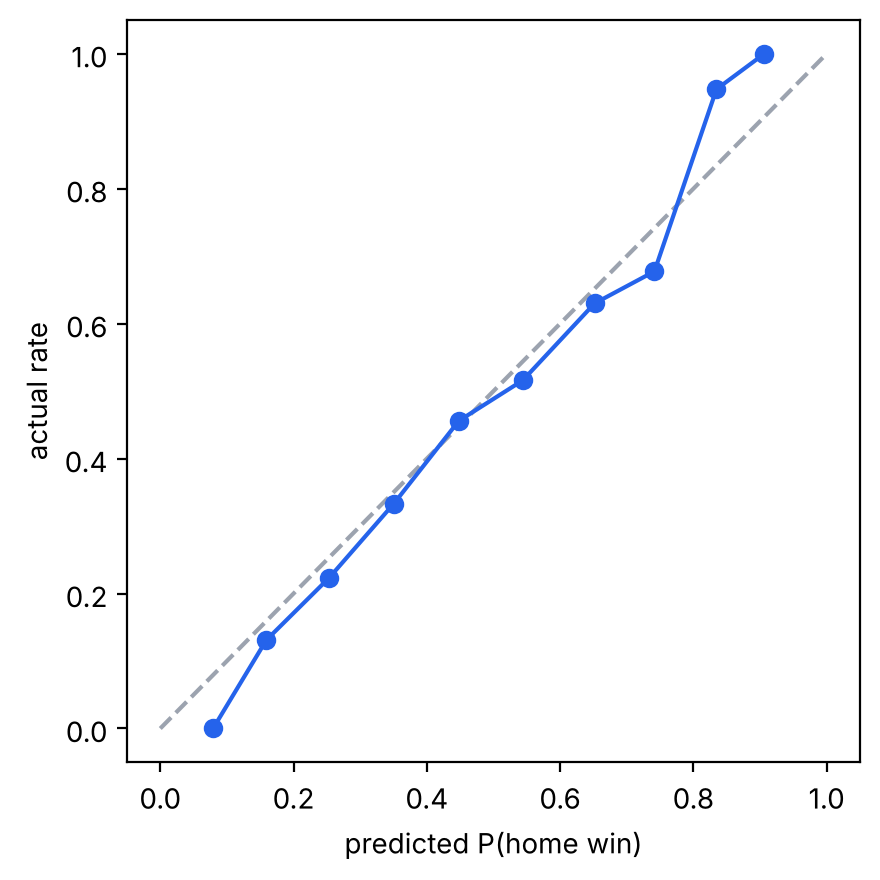

,pred,actual,n
0,0.079,0.000,11
1,0.159,0.131,61
2,0.253,0.223,103
3,0.351,0.333,135
4,0.448,0.456,136
5,0.544,0.516,126
6,0.652,0.630,100
7,0.741,0.677,62
8,0.835,0.947,19
9,0.906,1.000,1


In [4]:
pr = pd.read_csv(config.PREDICTIONS_FILE); te = pr[pr['set']=='test']
cal = ev.calibration_table(te['result'], te['pH'])
fig, ax = plt.subplots(figsize=(4.5,4.5)); ax.plot([0,1],[0,1],'--',color='#9ca3af'); ax.plot(cal['pred'], cal['actual'], 'o-', color='#2563eb')
ax.set_xlabel('predicted P(home win)'); ax.set_ylabel('actual rate'); plt.tight_layout(); plt.savefig(figs/'calibration_home.png', dpi=130); plt.show(); cal.round(3)

In [5]:
print(pd.crosstab(te['result'], te['pred']))

pred      A    H
result          
A       148  105
D        66  108
H        54  273


No draw is ever the most likely class, so the model never predicts one. This is a known limit of 3-class football models using only scores.

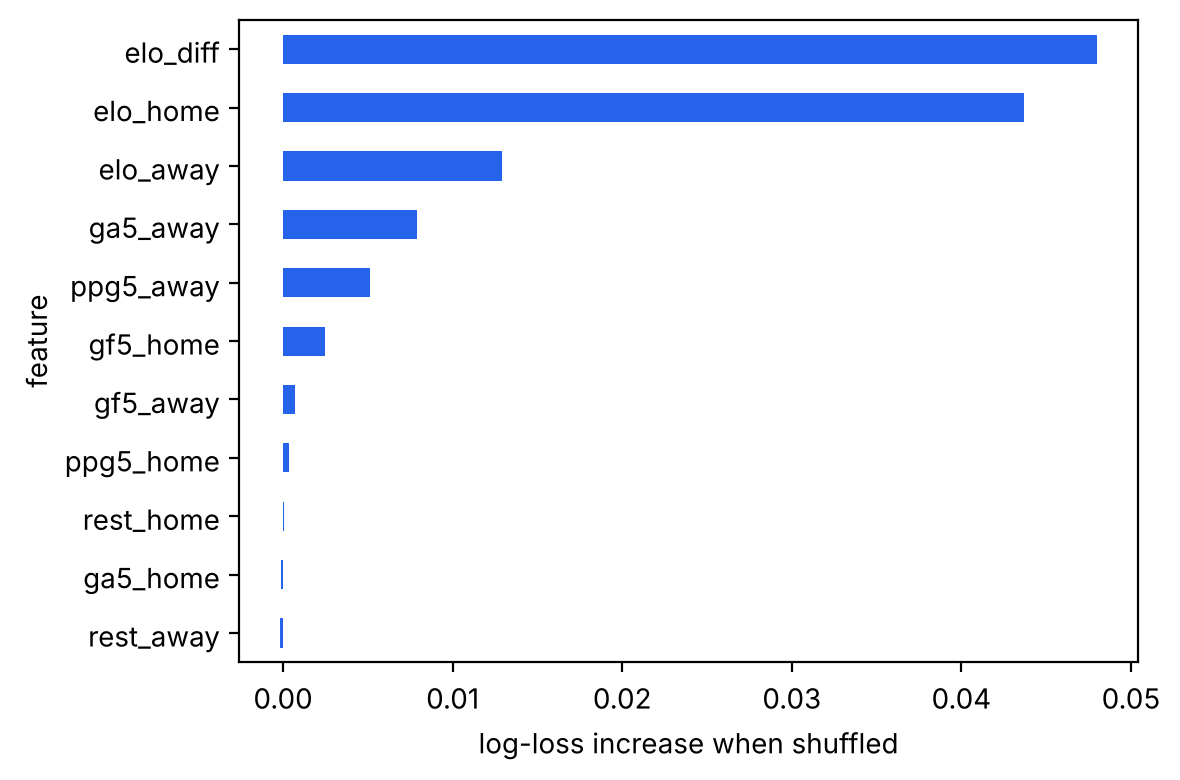

In [6]:
imp = pd.read_csv(config.REPORTS_DIR/'permutation_importance_test.csv').sort_values('logloss_increase')
ax = imp.plot.barh(x='feature', y='logloss_increase', legend=False, figsize=(6,4), color='#2563eb'); ax.set_xlabel('log-loss increase when shuffled')
plt.tight_layout(); plt.savefig(figs/'permutation_importance.png', dpi=130); plt.show()